# Lecture 15 — Measuring interactions in animal groups

We have already seen that simple interaction rules can generate complex and diverse collective behaviors. But, given a real-world example of a bird flock or fish school, how can you tell from experiments what interaction rules the animals use?

This companion follows the HTML lecture: measured fish responses, collective decisions and sensing, bird alignment dynamics, and fly density prediction. The locust experiments are presented through published figures and movies in the deck. Published figures remain experimental evidence; illustrative calculations are identified explicitly. Run all cells in the repository’s `swarming-course` environment.
The four questions in the lecture roadmap:

- **Fish.** How do local responses produce schools, mills, group decisions, and collective sensing?
- **Locusts.** Which cues start movement, and which determine direction?
- **Birds.** How do local interactions transmit a turn across the flock?
- **Flies.** How do crowding and habitat preference determine where animals accumulate?


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.special import gammaln, logsumexp
from scipy.optimize import minimize, brentq
from scipy.interpolate import CubicSpline
from scipy.signal import savgol_filter

ROOT = Path.cwd().parent if Path.cwd().name == 'lectures' else Path.cwd()
DATA = ROOT / 'data'
OUT = DATA / 'collective-motion'
OUT.mkdir(exist_ok=True)
COLORS = dict(ink='#f1ece2', amber='#f2b33d', blue='#67b7dc', red='#ed8170', green='#79be9e', muted='#aaa18e')
plt.rcParams.update({'figure.facecolor':'#12110e', 'axes.facecolor':'#12110e',
                     'text.color':COLORS['ink'], 'axes.labelcolor':COLORS['ink'],
                     'xtick.color':COLORS['muted'], 'ytick.color':COLORS['muted'],
                     'axes.edgecolor':'#797264', 'font.size':13, 'axes.labelsize':14,
                     'figure.figsize':(10.5,4), 'savefig.facecolor':'#12110e',
                     'axes.spines.top':False, 'axes.spines.right':False})
packet = {'schema':1, 'lecture':15, 'colors':COLORS, 'source_kind':{'fish':'measured trajectories', 'flies':'measured bin occupancies', 'birds':'measured 3D trajectories'}}
rng = np.random.default_rng(56715)

## Tracking a pair of mosquitofish

Forty pair trials, recorded at 40 frames/s. Positions are in mm.

Schaerf, Herbert-Read & Ward (2021), [article](https://doi.org/10.1098/rsif.2020.0925), [data](https://doi.org/10.6084/m9.figshare.14265787.v1).

HTML slides 12.

In [2]:
fish_archive = np.load(DATA/'flocking/fish-pairs-2021.npz')
fish_trials = {key:fish_archive[key] for key in fish_archive.files}
fish_dt = 1/40
assert len(fish_trials)==40
assert all(a.ndim==3 and a.shape[1:]==(2,2) for a in fish_trials.values())

def valid_runs(mask, minimum=1):
    edges = np.diff(np.r_[False, mask, False].astype(int))
    return [(int(a),int(b)) for a,b in zip(np.flatnonzero(edges==1),np.flatnonzero(edges==-1)) if b-a>=minimum]

fish_summary = pd.DataFrame([{'trial':key,'frames':len(p),'both tracked':int(np.isfinite(p).all(axis=(1,2)).sum())} for key,p in fish_trials.items()])
fish_summary.head()

,trial,frames,both tracked
0,group_01,24100,12675
1,group_02,26826,12575
2,group_03,24693,12400
3,group_04,20278,12040
4,group_05,24581,13656


### Acceleration changes speed and direction

$$
\mathbf a=\dot v\,\hat{\mathbf e}+v\dot\vartheta\,\hat{\mathbf e}_\perp.
$$

Local cubic fits estimate derivatives within each continuous tracked interval for the pair replay.

HTML slide 12.

For Katz’s published maps, the conditional mean is $\mathbf A(\mathbf r)=\langle\mathbf a_i(t)\mid\mathbf r_{ij}(t)=\mathbf r\rangle$: average the focal fish’s acceleration for each relative neighbor position at the same time. Other variables are averaged over in this two-dimensional map. The resulting effective force includes propulsion, hydrodynamics, and behavior; it does not isolate a causal social force. The later mosquitofish analysis instead measures the response over the following 0.2 s, as specified below.


In [3]:
def planar_kinematics(positions, dt, window=21):
    smooth = savgol_filter(positions, window, 3, axis=0)
    velocity = savgol_filter(positions, window, 3, deriv=1, delta=dt, axis=0)
    acceleration = savgol_filter(positions, window, 3, deriv=2, delta=dt, axis=0)
    speed = np.linalg.norm(velocity, axis=-1)
    direction = velocity / np.maximum(speed[...,None], 1e-12)
    speeding = np.sum(acceleration*direction, axis=-1)
    turning = (velocity[...,0]*acceleration[...,1]-velocity[...,1]*acceleration[...,0])/np.maximum(speed**2,1e-12)
    # A near-stationary velocity has no reliable measured heading.
    turning=np.where(speed>=5,turning,np.nan)
    return smooth, velocity, acceleration, speed, speeding, turning

replays=[]
for key in list(fish_trials)[:3]:
    p=fish_trials[key]; a,b=max(valid_runs(np.isfinite(p).all(axis=(1,2)),minimum=100),key=lambda ab:ab[1]-ab[0])
    b=min(b,a+2400)
    raw=p[a:b]; sm,v,acc,speed,speeding,turning=planar_kinematics(raw,fish_dt)
    keep=np.arange(12,len(raw)-12,4)
    rows=np.column_stack(((a+keep)*fish_dt,raw[keep].reshape(len(keep),4),v[keep].reshape(len(keep),4),turning[keep]))
    replays.append({'trial':key,'rows':rows,'dt':0.1,'source_start_frame':a,'position_units':'mm'})
packet['fish_replays']=replays


### Neighbor position in the focal fish's frame

$x$ points forward and $y$ points left. Encounter headings use the preceding 0.2 s of displacement; the turning response uses the next 0.2 s.

HTML slides 12.

In [4]:
def body_coordinates(displacement, focal_velocity):
    e=focal_velocity/np.maximum(np.linalg.norm(focal_velocity,axis=-1,keepdims=True),1e-12)
    return np.stack((np.sum(displacement*e,axis=-1),-displacement[...,0]*e[...,1]+displacement[...,1]*e[...,0]),axis=-1)

def wrap_angle(angle):
    return np.arctan2(np.sin(angle),np.cos(angle))

# Features use the preceding 0.2 s of displacement. The response uses the next 0.2 s.
# Trial splits therefore do not share frames, and predictors do not use future positions.
fish_encounters=[]
hop=8
for trial,(key,p) in enumerate(fish_trials.items(),1):
    t=np.arange(hop,len(p)-hop,4)
    now=(p[t]-p[t-hop])/(hop*fish_dt)
    after=(p[t+hop]-p[t])/(hop*fish_dt)
    for focal in [0,1]:
        neighbor=1-focal
        displacement=p[t,neighbor]-p[t,focal]
        body=body_coordinates(displacement,now[:,focal])
        speed=np.linalg.norm(now[:,focal],axis=1)
        partner_speed=np.linalg.norm(now[:,neighbor],axis=1)
        heading=np.arctan2(now[:,focal,1],now[:,focal,0])
        future_heading=np.arctan2(after[:,focal,1],after[:,focal,0])
        delta=wrap_angle(np.arctan2(now[:,neighbor,1],now[:,neighbor,0])-heading)
        turn=wrap_angle(future_heading-heading)/(hop*fish_dt)
        speeding=(np.linalg.norm(after[:,focal],axis=1)-speed)/(hop*fish_dt)
        r=np.linalg.norm(body,axis=1)
        good=np.isfinite(np.column_stack((body,delta,speed,partner_speed,turn,speeding))).all(axis=1)&(r>5)&(r<180)&(speed>5)&(speed<300)&(partner_speed>5)&(partner_speed<300)
        for j in np.flatnonzero(good):
            fish_encounters.append((trial,int(t[j]),focal,body[j,0],body[j,1],r[j],delta[j],speed[j],partner_speed[j],turn[j],speeding[j]))
enc=np.array(fish_encounters)
assert len(enc)>1000
print(f'{len(enc):,} eligible encounters across {len(np.unique(enc[:,0]))} trials; overlapping observations remain grouped by trial.')

162,308 eligible encounters across 40 trials; overlapping observations remain grouped by trial.


### Mean turning around a neighbor

$$
A_{\rm turn}(x,y)=\left\langle\dot\vartheta_i\mid x_{ij}=x,\ y_{ij}=y\right\rangle.
$$

The map averages the subsequent turning response at each relative neighbor position. Bins require at least 20 observations.

HTML slides 13.

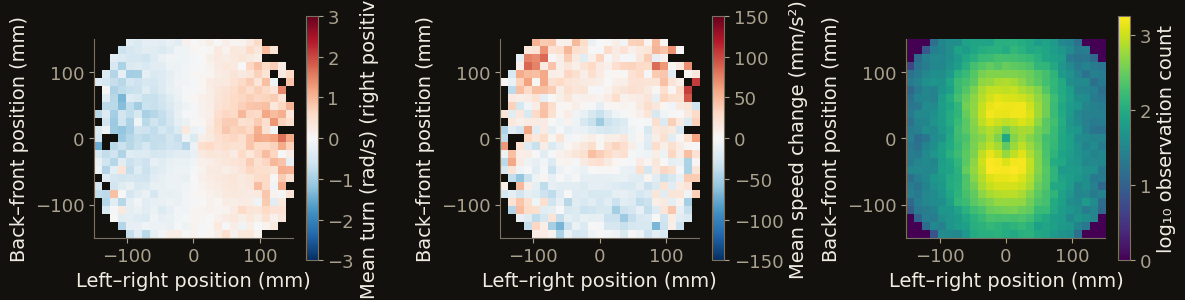

In [5]:
def response_map(x,y,values,edges,minimum=20):
    counts,_,_=np.histogram2d(y,x,bins=(edges,edges))
    total,_,_=np.histogram2d(y,x,bins=(edges,edges),weights=values)
    mean=np.divide(total,counts,out=np.full_like(total,np.nan),where=counts>=minimum)
    return mean,counts

map_edges=np.linspace(-150,150,26)
turn_map,map_counts=response_map(enc[:,3],enc[:,4],enc[:,9],map_edges)
speed_map,_=response_map(enc[:,3],enc[:,4],enc[:,10],map_edges)
fig,ax=plt.subplots(1,3,figsize=(12,3.8))
for axis,values,label,cm,lim in zip(ax,[turn_map,speed_map,np.log10(np.maximum(map_counts,1))],['Mean turn (rad/s)','Mean speed change (mm/s²)','log₁₀ observation count'],['RdBu_r','RdBu_r','viridis'],[3,150,None]):
    display_values=values[::-1,:].T
    if label=='Mean turn (rad/s)': display_values=-display_values
    artist=axis.imshow(display_values,origin='lower',extent=(-150,150,-150,150),cmap=cm,vmin=-lim if lim else None,vmax=lim,aspect='equal')
    axis.set(xlabel='Left–right position (mm)',ylabel='Back–front position (mm)');fig.colorbar(artist,ax=axis,shrink=.75,label=label+ (' (right positive)' if label=='Mean turn (rad/s)' else ''))
plt.tight_layout();plt.show()
packet['fish_maps']={'edges':map_edges,'turn':turn_map,'speeding':speed_map,'counts':map_counts,'eligible_observations':len(enc),'trials':40,'minimum_observations':20}

### Turning maps from known interaction rules

$$
\dot\vartheta=k_a\sin\Delta\vartheta+k_p\frac yr-k_r\frac yr e^{-(r/35)^2}.
$$

The schooling movie motivates a test: does coordination come from matching headings or following positions? Synthetic encounters hold positions and noise fixed while the three coefficients change. In the HTML comparison, heading matching is blue and solid; position following is orange and dashed.

HTML slides 5.

In [6]:
def interaction_rule(x,y,delta,alignment=1.,attraction=1.,repulsion=1.):
    r=np.maximum(np.hypot(x,y),1e-9)
    lateral=y/r
    turn=alignment*np.sin(delta)+attraction*lateral-repulsion*lateral*np.exp(-(r/35)**2)
    speeding=40*np.tanh((r-55)/45)*x/r
    return turn,speeding

synthetic_x=rng.uniform(-150,150,12000);synthetic_y=rng.uniform(-150,150,12000)
synthetic_delta=0.5*np.arctan2(synthetic_y,synthetic_x+170)+rng.normal(0,.25,12000)
synthetic_noise=rng.normal(0,.35,12000)
synthetic={}
for name,weights in [('Heading alignment',(2.,0.,0.)),('Position response',(0.,2.,2.5))]:
    truth,_=interaction_rule(synthetic_x,synthetic_y,synthetic_delta,*weights)
    observed=truth+synthetic_noise
    m,c=response_map(synthetic_x,synthetic_y,observed,map_edges,minimum=5)
    synthetic[name]={'map':m,'counts':c,'weights':weights}
packet['synthetic_maps']=synthetic
packet['synthetic_encounters']=np.column_stack((synthetic_x[:1000],synthetic_y[:1000],synthetic_delta[:1000],synthetic_noise[:1000]))

### Position following can align a pair

A driven leader makes the same turns in both simulations. Its follower either copies heading or steers toward the leader's position.

Both followers adjust speed toward a 55 mm forward gap. Time step: 0.01 s.

HTML slides 10.

In [7]:
def pair_model_step(position,heading,speed,time,dt,mode):
    p=np.asarray(position,float);h=np.asarray(heading,float);s=np.asarray(speed,float)
    e=np.column_stack((np.cos(h),np.sin(h)))
    body=body_coordinates((p[0]-p[1])[None,:],(e[1]*s[1])[None,:])[0]
    delta=wrap_angle(h[0]-h[1])
    omega_leader=.28*np.sin(.7*time)+.12*np.sin(1.3*time)
    omega_follower=2.0*np.sin(delta) if mode=='alignment' else 2.0*np.arctan2(body[1],body[0])
    s_new=np.array([50.,np.clip(s[1]+dt*(.7*(body[0]-55)-1.8*(s[1]-50)),10,100)])
    h_new=h+dt*np.array([omega_leader,omega_follower])
    e_new=np.column_stack((np.cos(h_new),np.sin(h_new)))
    return p+dt*s_new[:,None]*e_new,h_new,s_new

pair_histories={}
for mode in ['alignment','position']:
    position=np.array([[55.,0.],[0.,0.]]);heading=np.zeros(2);speed=np.full(2,50.)
    rows=[];phi=[]
    for j in range(4000):
        position,heading,speed=pair_model_step(position,heading,speed,j*.01,.01,mode)
        if j%10==0:
            rows.append([j*.01,*position.ravel(),*heading,*speed])
            phi.append(float(np.hypot(np.cos(heading).mean(),np.sin(heading).mean())))
    rows=np.array(rows)
    pair_histories[mode]={'rows':rows,'phi':phi,'mean_phi':float(np.mean(phi))}
packet['pair_models']=pair_histories
print('Mean polarization in the two different follower models:', {k:round(v['mean_phi'],4) for k,v in pair_histories.items()})

Mean polarization in the two different follower models: {'alignment': 0.9988, 'position': 0.9936}


## Testing pairwise averaging

The golden-shiner triplet figures test a prediction made from pair responses. For a specified encounter, the averaging hypothesis is

$$\mathbf a_{i,\mathrm{pred}}^{(3)}=\tfrac12[\mathbf A^{(2)}(\mathbf q_{ij})+\mathbf A^{(2)}(\mathbf q_{ik})].$$

The available mosquitofish data contain pairs only. The following function implements the prediction; the experimental triplet comparison is [Katz et al. (2011), Figure 3](https://doi.org/10.1073/pnas.1107583108).

HTML slides 15.
Katz’s turning residuals show additional restoring responses when the focal fish lies between its neighbors. Two same-side neighbors have approximately the influence of one; the result is not same-side amplification.


In [8]:
def triplet_prediction(pair_responses, coefficient=0.5):
    return coefficient*np.asarray(pair_responses,float).sum(axis=0)

pair_example=np.array([[20.,8.],[-10.,5.]])
assert np.allclose(triplet_prediction(pair_example),[5.,6.5])


## Schooling, milling, and switching

- Neighboring fish can move together in a traveling school or a rotating mill.
- Fixed-rule fish models can switch between these states.
- In shiners, a turn at the front can curl the school into a mill; a wall encounter can unravel a mill.
- Tetras switch under fixed conditions, and spend more time milling as confinement increases.

![School and mill](../media/collective-motion/tunstrom-school-and-mill.png)

![Switching at fixed conditions](../media/collective-motion/lafoux-fixed-condition-switching.png)

![Time spent milling versus confinement density](../media/collective-motion/lafoux-confinement-milling.png)

Confinement density is $\rho=N/S$, with $N$ fish and tank area $S$. Marker shapes are square: 1 m², circle: 0.5 m², triangle: 0.25 m². Color indicates the number of fish. This is density over the tank area, not the area occupied by the school.

Sources: [Tunstrøm et al. (2013)](https://doi.org/10.1371/journal.pcbi.1002915), [Calovi et al. (2014)](https://doi.org/10.1088/1367-2630/16/1/015026), [Lafoux et al. (2024)](https://doi.org/10.1103/PhysRevE.110.034613).

HTML slides 18–21.


## A preferred direction in an aligned group

This globally coupled heading model isolates personal preference and social response. It is a teaching reduction of the question in [Couzin et al. (2005)](https://doi.org/10.1038/nature03236), not a numerical reproduction of their spatial model.

$$\dot\vartheta_i=\frac{J_{\rm align}}{N}\sum_j\sin(\vartheta_j-\vartheta_i)+h_i\sin(\vartheta_{\rm target}-\vartheta_i).$$

Here the target heading is zero. Without noise, a small persistent informed fraction can eventually steer the whole globally coupled group; the plot compares finite-time responses.

HTML slides 22.

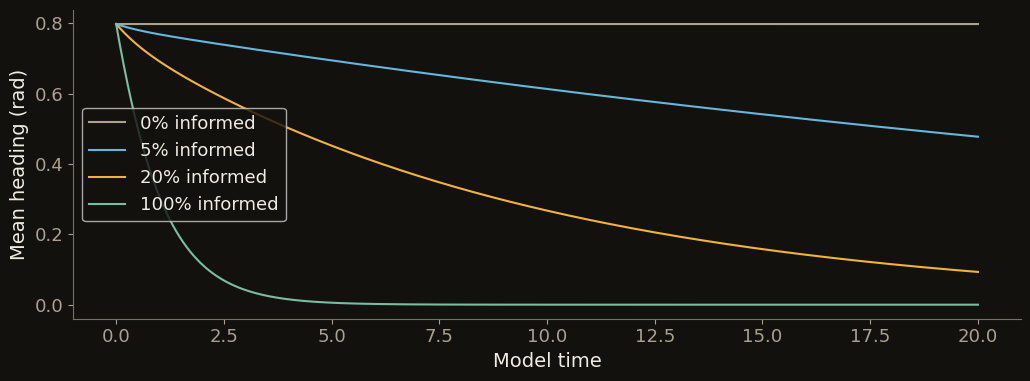

In [9]:
def informed_heading_step(heading,fraction=0.1,preference=1.,alignment=1.,dt=0.01):
    heading=np.asarray(heading,float)
    c,s=np.cos(heading).mean(),np.sin(heading).mean()
    informed=np.arange(len(heading))<round(fraction*len(heading))
    rate=alignment*(s*np.cos(heading)-c*np.sin(heading))-informed*preference*np.sin(heading)
    return heading+dt*rate

heading_start=0.8+0.35*np.sin(np.arange(40)*2.4)
fig,ax=plt.subplots()
for frac,color in zip([0.,.05,.2,1.],['#aaa18e','#67b7dc','#f2b33d','#79be9e']):
    h=heading_start.copy();means=[]
    for j in range(2001):
        means.append(np.arctan2(np.sin(h).mean(),np.cos(h).mean()))
        h=informed_heading_step(h,frac)
    ax.plot(np.arange(2001)*.01,means,color=color,label=f'{100*frac:g}% informed')
ax.set(xlabel='Model time',ylabel='Mean heading (rad)');ax.legend();plt.tight_layout();plt.show()


## Speed differences across a cohesive group

Solitary fish perform slightly above the null, while larger groups track dark patches much more effectively. The golden-shiner experiment shows speed modulation by local light and strong social steering ([Berdahl et al., 2013](https://doi.org/10.1126/science.1225883)). This two-point example isolates one kinematic consequence. It is not a rigid-body model of a real school or a refit of the experiment.

$$\dot\vartheta=(v_{\rm right}-v_{\rm left})/d\simeq-\partial_\perp v.$$

Both ends sample the same light field. Turning the speed response off leaves the initial direction unchanged.

HTML slides 32.

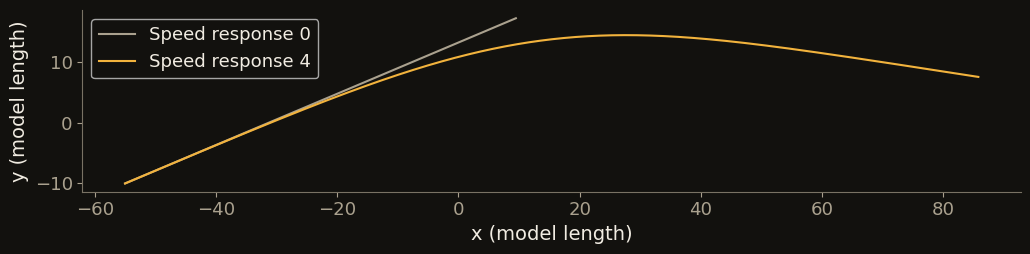

In [10]:
def light_field(x,y,time):
    cx,cy=15*np.sin(time/35),10*np.cos(time/40)
    return 1-0.9*np.exp(-((np.asarray(x)-cx)**2+(np.asarray(y)-cy)**2)/(2*22**2))

def sensing_step(state,time,dt=.02,separation=12.,gain=4.):
    x,y,heading=state
    nx,ny=-np.sin(heading),np.cos(heading)
    vl=2+gain*light_field(x+separation*nx/2,y+separation*ny/2,time)
    vr=2+gain*light_field(x-separation*nx/2,y-separation*ny/2,time)
    speed=(vl+vr)/2
    return np.array([x+dt*speed*np.cos(heading),y+dt*speed*np.sin(heading),heading+dt*(vr-vl)/separation])

fig,ax=plt.subplots()
for gain,color in [(0.,COLORS['muted']),(4.,COLORS['amber'])]:
    state=np.array([-55.,-10.,.4]);path=[]
    for j in range(1751):
        path.append(state.copy());state=sensing_step(state,j*.02,gain=gain)
    path=np.asarray(path);ax.plot(path[:,0],path[:,1],color=color,label=f'Speed response {gain:g}')
ax.set(xlabel='x (model length)',ylabel='y (model length)',aspect='equal');ax.legend();plt.tight_layout();plt.show()


## Take Home Messages

- Following neighbors can align a school without copying headings.
- Local interactions can support more than one collective state.
- Uninformed fish can change a group’s decision.
- A school tracks environmental gradients better than individual fish.

HTML slide 33.


## Take Home Messages

- Increasing density can turn disordered movement into collective marching.
- Contact helps initiate walking; vision guides direction.
- Social experience changes how locusts respond to neighbors.
- Choosing between targets is not the same as averaging them.

HTML slide 46.


## Measuring the timing of a collective turn

Three synchronized cameras reconstruct individual starling trajectories. The HTML lecture shows the flock recording and the measured trajectories before introducing the timing analysis.

![Two birds turning at different times](../media/collective-motion/attanasi-two-bird-delay.png)

The acceleration perpendicular to flight measures turning. Red and blue are two birds in the same flock. The time shift that maximizes overlap of their radial-acceleration signals gives their delay. Comparing pairs establishes the turning order. The number turned, together with flock density, estimates how far the turn has spread. In the measured flocks this distance grows approximately linearly with time. The following alignment model is tested against that result.

Attanasi et al. (2014), [Information transfer and behavioural inertia in starling flocks](https://doi.org/10.1038/nphys3035), Figure 1d and Supplementary Movies 1–2. This panel shows published measurements; the following Python cells develop the alignment model.

HTML slides 48–50.


## Alignment modes on a fixed network

For a symmetric fixed network, $\dot{\delta\boldsymbol\vartheta}=-J_{\rm align}\boldsymbol\Lambda_{\rm align}\delta\boldsymbol\vartheta+\boldsymbol\xi$. Each positive mode relaxes with $\tau_\alpha=(J_{\rm align}\lambda_\alpha)^{-1}$. A nearest-neighbor ring makes the eigenvalues explicit:

$$\lambda_k=4\sin^2(\pi k/N).$$

This planar example explains the calculation used in dynamical inference. The source starling estimates are the published results in [Mora et al. (2016)](https://doi.org/10.1038/nphys3846), not fits to these generated examples.

## Separate the neighbors’ headings from the bird’s own heading


- $\delta\vartheta_i$: bird $i$’s heading deviation from a common reference direction.
- $w_{ij}$: influence of bird $j$ on bird $i$. Sum over all birds; $w_{ii}=0$.
$$
\dot{\delta\vartheta}_i=J_{\rm align}\sum_j w_{ij}(\delta\vartheta_j-\delta\vartheta_i)+\xi_i
$$

$$
=J_{\rm align}\left[\underbrace{\sum_jw_{ij}\delta\vartheta_j}_{\text{neighbors}}-\underbrace{\left(\sum_jw_{ij}\right)\delta\vartheta_i}_{\text{bird }i}\right]+\xi_i
$$

- The same alignment rule, with the two contributions written separately.

## The Laplacian collects these coefficients into a matrix


- Three birds in a chain: $1\leftrightarrow2\leftrightarrow3$, with unit weight on each link.
$$
\begin{pmatrix}\dot{\delta\vartheta}_1\\\dot{\delta\vartheta}_2\\\dot{\delta\vartheta}_3\end{pmatrix}=-J_{\rm align}\underbrace{\begin{pmatrix}1&-1&0\\-1&2&-1\\0&-1&1\end{pmatrix}}_{\boldsymbol\Lambda_{\rm align}}\begin{pmatrix}\delta\vartheta_1\\\delta\vartheta_2\\\delta\vartheta_3\end{pmatrix}+\boldsymbol\xi
$$

- Diagonal: total weight of a bird’s neighbors. Off-diagonal: negative interaction weight.
- Row 2 gives $\dot{\delta\vartheta}_2=J_{\rm align}(\delta\vartheta_1-2\delta\vartheta_2+\delta\vartheta_3)+\xi_2$.
$$
\dot{\delta\boldsymbol\vartheta}=-J_{\rm align}\boldsymbol\Lambda_{\rm align}\delta\boldsymbol\vartheta+\boldsymbol\xi
$$


## A mode is a heading pattern that keeps its shape as it relaxes


- Use fixed, symmetric interaction weights. An eigenvector specifies one heading deviation per bird.
$$
\boldsymbol\Lambda_{\rm align}\mathbf u_\alpha=\lambda_\alpha\mathbf u_\alpha
$$
| Three-bird pattern | Eigenvalue | Heading differences |
| --- | --- | --- |
| $(1,1,1)$ | $0$ | All birds turn together |
| $(1,0,-1)$ | $1$ | Heading changes across the chain |
| $(1,-2,1)$ | $3$ | Middle bird opposes both neighbors |


- These three patterns can be combined to describe any small heading perturbation of the three birds.
- Uniform rotation creates no disagreement, so alignment does not restore it.

## Each mode reduces the coupled equations to one decay equation


- Follow one mode: $\delta\boldsymbol\vartheta(t)=c_\alpha(t)\mathbf u_\alpha$. Set noise to zero to calculate its relaxation.
$$
\dot c_\alpha\mathbf u_\alpha=-J_{\rm align}c_\alpha\boldsymbol\Lambda_{\rm align}\mathbf u_\alpha=-J_{\rm align}\lambda_\alpha c_\alpha\mathbf u_\alpha
$$

$$
\dot c_\alpha=-J_{\rm align}\lambda_\alpha c_\alpha\quad\Longrightarrow\quad c_\alpha(t)=c_\alpha(0)e^{-J_{\rm align}\lambda_\alpha t}
$$

$$
\tau_\alpha=\frac{1}{J_{\rm align}\lambda_\alpha}\qquad(\lambda_\alpha>0)
$$

- The middle-against-ends pattern decays three times faster than the gradual pattern in the three-bird example.

## Local alignment can be fast while a broad heading pattern relaxes slowly


- Birds align with their connected neighbors.
- A smooth heading pattern produces small differences between neighbors and relaxes slowly.
- A rapidly varying pattern produces larger differences and relaxes faster.
$$
\text{Decay rate}=J_{\rm align}\lambda_\alpha
$$

- Local relaxation and relaxation across the whole flock are different time scales.

HTML slides 52–57.

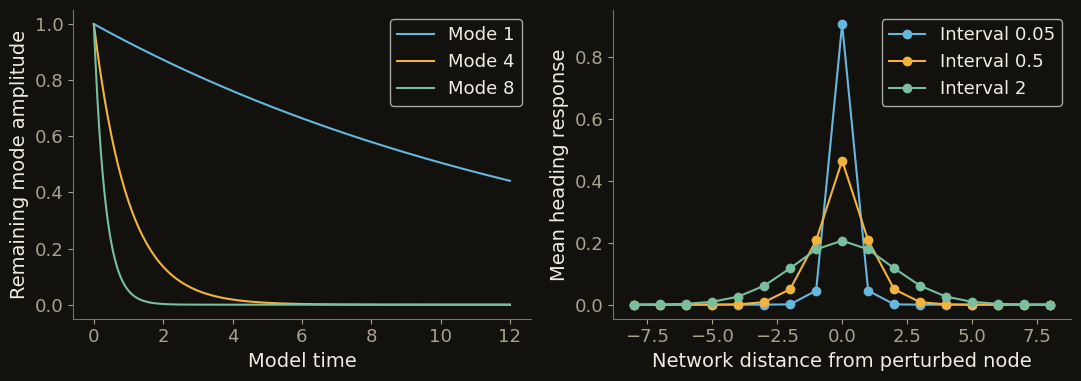

In [11]:
from scipy.linalg import expm

def ring_laplacian(size=24):
    identity=np.eye(size)
    return 2*identity-np.roll(identity,1,axis=0)-np.roll(identity,-1,axis=0)

def ring_kernel(size=24,rate=1.,interval=.5):
    modes=np.arange(size);lam=4*np.sin(np.pi*modes/size)**2
    return np.array([np.mean(np.exp(-rate*lam*interval)*np.cos(2*np.pi*modes*j/size)) for j in range(size)])

def network_mode(geometry='ring', size=24, mode=1):
    """Exact eigenmode of a ring, open chain, or open rectangular lattice."""
    rows, cols = 1, size
    if geometry == 'grid':
        rows = int(np.sqrt(size))
        while size % rows:
            rows -= 1
        cols = size // rows
    period = cols if geometry == 'grid' else size
    i = np.arange(size) % cols if geometry == 'grid' else np.arange(size)
    if geometry == 'ring':
        eigenvalue = 2 - 2*np.cos(2*np.pi*mode/period)
        values = np.cos(2*np.pi*mode*i/period)
    else:
        eigenvalue = 2 - 2*np.cos(np.pi*mode/period)
        values = np.cos(np.pi*mode*(i + .5)/period)
    return rows, cols, eigenvalue, values

lap=ring_laplacian();eigenvalues,eigenvectors=np.linalg.eigh(lap)
assert np.allclose(lap.sum(axis=1),0)
assert np.allclose(ring_kernel(),expm(-.5*lap)[:,0],atol=1e-14)
fig,ax=plt.subplots(1,2,figsize=(11,4))
times=np.linspace(0,12,241)
for mode,color in [(1,COLORS['blue']),(4,COLORS['amber']),(8,COLORS['green'])]:
    lam=4*np.sin(np.pi*mode/24)**2
    ax[0].plot(times,np.exp(-lam*times),color=color,label=f'Mode {mode}')
for interval,color in [(.05,COLORS['blue']),(.5,COLORS['amber']),(2.,COLORS['green'])]:
    distance=np.arange(-8,9);kernel=ring_kernel(interval=interval)
    ax[1].plot(distance,kernel[distance%24],'o-',color=color,label=f'Interval {interval:g}')
ax[0].set(xlabel='Model time',ylabel='Remaining mode amplitude');ax[1].set(xlabel='Network distance from perturbed node',ylabel='Mean heading response');ax[0].legend();ax[1].legend();plt.tight_layout();plt.show()


## Bird positions define a candidate interaction network

Track each bird’s position and heading in successive frames. For bird $i$, rank its neighbors by distance: $k_{ij}=1$ is its nearest neighbor. Assume an exponential influence:

$$w_{ij}=e^{-k_{ij}/n_c}.$$

For each candidate interaction range $n_c$, the positions determine a candidate alignment matrix $\boldsymbol\Lambda_{\rm align}$. The ranks, weights and matrix change as birds move. The range itself is fitted, not known in advance.

HTML slide 58.


## Fit the interaction rule to changes between frames

For a candidate network held fixed between adjacent frames, the expected change in the planar reference model is

$$\mathbb E[\delta\boldsymbol\vartheta(t+\Delta t)\mid\delta\boldsymbol\vartheta(t)]=e^{-J_{\rm align}\boldsymbol\Lambda_{\rm align}\Delta t}\,\delta\boldsymbol\vartheta(t).$$

Noise determines the scatter around the mean. Fit the interaction range, alignment strength and noise to maximize the probability of the measured next-frame headings. The matrix exponential accounts for alignment during the frame interval. The authors used three-dimensional flight directions; the planar model here illustrates the method.

For one normalized mode, $\tau_\alpha^{-1}=J_{\rm align}\lambda_\alpha$, and its noise variance is $D_{\rm ang}\tau_\alpha[1-e^{-2\Delta t/\tau_\alpha}]$. The Euler approximation replaces the exponential by $1-\Delta t/\tau_\alpha$ and requires $\Delta t\ll\tau_\alpha$.

HTML slide 59.


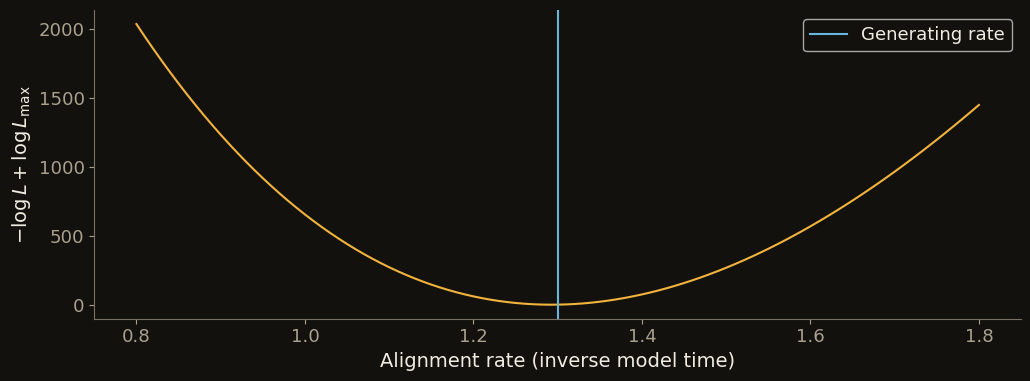

Generating rate 1.300; inferred rate 1.293


In [12]:
from scipy.optimize import minimize_scalar

def modal_transition(eigenvalues,rate,noise,interval):
    eigenvalues=np.asarray(eigenvalues,float)
    decay=np.exp(-rate*eigenvalues*interval)
    variance=noise*(-np.expm1(-2*rate*eigenvalues*interval))/(rate*eigenvalues)
    return decay,variance

positive=eigenvalues[1:];true_rate=1.3;noise_strength=.025;sample_interval=.7
local_rng=np.random.default_rng(151516)
decay,variance=modal_transition(positive,true_rate,noise_strength,sample_interval)
y=local_rng.normal(size=(2501,len(positive)))*np.sqrt(noise_strength/(true_rate*positive))
for t in range(2500):y[t+1]=decay*y[t]+local_rng.normal(size=len(positive))*np.sqrt(variance)
def transition_nll(rate):
    decay,variance=modal_transition(positive,rate,noise_strength,sample_interval)
    residual=y[1:]-decay*y[:-1]
    return .5*np.sum(np.log(2*np.pi*variance)+residual**2/variance)
fit=minimize_scalar(transition_nll,bounds=(.2,3.),method='bounded')
assert abs(fit.x-true_rate)<.08
fig,ax=plt.subplots();rates=np.linspace(.8,1.8,101);loss=np.array([transition_nll(v) for v in rates]);ax.plot(rates,loss-loss.min(),color=COLORS['amber']);ax.axvline(true_rate,color=COLORS['blue'],label='Generating rate');ax.set(xlabel='Alignment rate (inverse model time)',ylabel=r'$-\log L+\log L_{\max}$');ax.legend();plt.tight_layout();plt.show()
print(f'Generating rate {true_rate:.3f}; inferred rate {fit.x:.3f}')


## Our model predicts diffusion, but starling turns travel as waves

- The previous alignment model, applied to a chain of neighbors, predicts **diffusive spreading**:
$$
\partial_t\delta\vartheta=D_\vartheta\partial_x^2\delta\vartheta
$$

$$
\text{MSD}\propto t\quad\Longrightarrow\quad\text{spread}\propto\sqrt{t}
$$

- As in particle diffusion, spread grows as the square root of time; here it is a heading disturbance that spreads, not a bird trajectory.
- **Starling measurements:** the distance reached grows approximately linearly with time during the turn’s initial spread.
- **A nearly constant propagation speed—a wave.**

## A bird’s turning rate persists while its neighbors respond

- In the previous model, heading differences set the turning rate immediately.
- Here, neighbors change a bird’s turning rate; damping reduces it.

$$
\underbrace{\partial_t^2\delta\vartheta}_{\text{angular acceleration}}=\underbrace{c_s^2\partial_x^2\delta\vartheta}_{\text{response to neighbors}}-\underbrace{\gamma_{\rm turn}\partial_t\delta\vartheta}_{\text{damping of turning}}
$$

- Without neighbor input, the turning rate decays as $e^{-\gamma_{\rm turn}t}$.
- Without damping, a change in heading travels at speed $c_s$ without fading.
- This persistence of turning is **behavioral inertia**.


## The wave solution gives both a speed and a decay time

- For a sinusoidal heading pattern, $\delta\vartheta\propto e^{i(kx-\omega t)}$, with $k=2\pi/\text{wavelength}$:
$$
-\omega^2-i\gamma_{\rm turn}\omega=-c_s^2k^2\quad\Longrightarrow\quad\omega_\pm=-\frac{i\gamma_{\rm turn}}2\pm\sqrt{c_s^2k^2-\frac{\gamma_{\rm turn}^2}{4}}
$$

- When damping is weak, $\gamma_{\rm turn}\ll2c_s|k|$, the real heading pattern is approximately
$$
\delta\vartheta(x,t)\simeq\underbrace{A_0e^{-\gamma_{\rm turn}t/2}}_{\text{shrinking amplitude}}\qquad\underbrace{\cos[k(x\mp c_st)]}_{\text{pattern moving at }c_s}
$$

- **Propagation speed:** $c_s$. **Amplitude decay time:** $2/\gamma_{\rm turn}$.

## Persistent turning sends the disturbance outward

- **Same initial heading change:** diffusion broadens it; turning dynamics produces two traveling signals.
- Color shows heading deviation. Sloping bands show propagation; increasing damping weakens them.

## Damping would weaken the turn as it crosses the flock

- A wave can travel but still fade before it reaches the other side of the flock.
$$
\frac{A(L)}{A_0}=e^{-t_{\rm cross}/\tau_{\rm decay}}
$$
$t_{\rm cross}=L/c_s$: time to cross the flock.
$\tau_{\rm decay}=2/\gamma_{\rm turn}$: amplitude decay time.
- **Strong damping predicts weaker turns in birds reached later.**
- Peak turning accelerations test whether that weakening actually occurs.

## Starling turns cross the flock with little loss of strength

- **Red birds turn first, green birds next, blue birds last.** The curves show their radial accelerations.
- Later birds turn almost as strongly. The inset shows little decline in peak acceleration across the turning order.
- **The turn crosses the flock before it fades.** Together with the constant propagation speed, this is the behavior of a weakly damped wave.
- Local interactions can coordinate a whole-flock turn.

HTML slides 61–66.

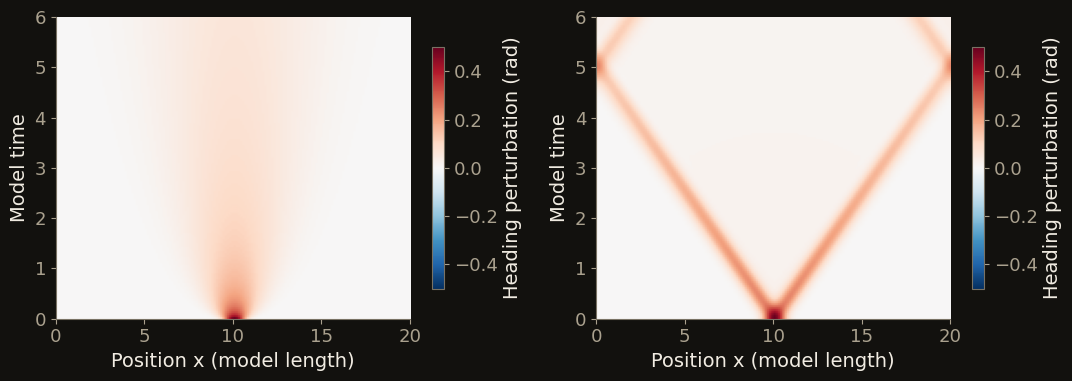

In [13]:
def propagation_step(angle,rate,dt,dx,model='wave',diffusivity=1.,c=2.,damping=.3):
    lap=(np.roll(angle,-1)-2*angle+np.roll(angle,1))/dx**2
    if model=='diffusion':
        return angle+dt*diffusivity*lap,np.zeros_like(rate)
    next_rate=(rate+dt*c*c*lap)/(1+damping*dt)
    return angle+dt*next_rate,next_rate

wave_x=np.arange(160)*.125
wave_initial=.5*np.exp(-((wave_x-10)/.6)**2)
wave_histories={}
for model in ['diffusion','wave']:
    angle=wave_initial.copy();rate=np.zeros_like(angle);frames=[]
    for k in range(1501):
        if k%10==0:frames.append(angle.copy())
        angle,rate=propagation_step(angle,rate,.004,.125,model=model)
    wave_histories[model]=np.array(frames)
fig,ax=plt.subplots(1,2,figsize=(11,4))
for axis,model in zip(ax,['diffusion','wave']):
    a=axis.imshow(wave_histories[model],origin='lower',aspect='auto',extent=(0,20,0,6),vmin=-.5,vmax=.5,cmap='RdBu_r')
    axis.set(xlabel='Position x (model length)',ylabel='Model time');fig.colorbar(a,ax=axis,label='Heading perturbation (rad)',shrink=.8)
plt.tight_layout();plt.show()
packet['propagation']={'x':wave_x,'initial':wave_initial,'dt':.004,'dx':.125,'histories':wave_histories,'frame_dt':.04}

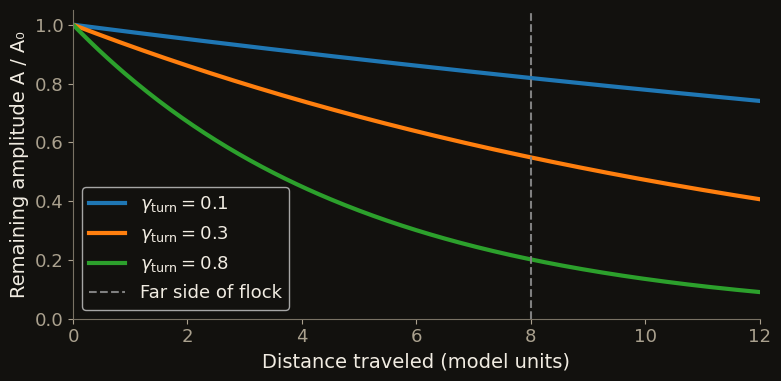

In [14]:
def turn_reach(distance, speed, damping):
    """Weak-damping traveling-wave amplitude envelope; distances in model units."""
    return np.exp(-damping*np.asarray(distance)/(2*speed))

assert np.allclose(turn_reach([0, 4, 8], 2, .5), [1, np.exp(-.5), np.exp(-1)])
assert np.allclose(turn_reach([0, 12], 2, 0), [1, 1])
distance = np.linspace(0, 12, 241)
fig, ax = plt.subplots(figsize=(8, 4))
for damping in [.1, .3, .8]:
    ax.plot(distance, turn_reach(distance, 2, damping), lw=3,
            label=fr"$\gamma_{{\rm turn}}={damping}$")
ax.axvline(8, color="0.5", ls="--", label="Far side of flock")
ax.set(xlabel="Distance traveled (model units)", ylabel="Remaining amplitude A / A₀",
       xlim=(0, 12), ylim=(0, 1.05))
ax.legend()
plt.tight_layout()
plt.show()


## Propagation and damping of heading modes

For $e^{i(kx-\omega t)}$, diffusion gives $\omega=-iD_\vartheta k^2$. The damped turning-wave equation gives

$$\omega_\pm=-i\gamma_{\rm turn}/2\pm\sqrt{c_s^2k^2-\gamma_{\rm turn}^2/4}.$$

A negative imaginary part is decay with this time convention. Both branches become purely relaxational below the propagation threshold.

HTML slides 63.

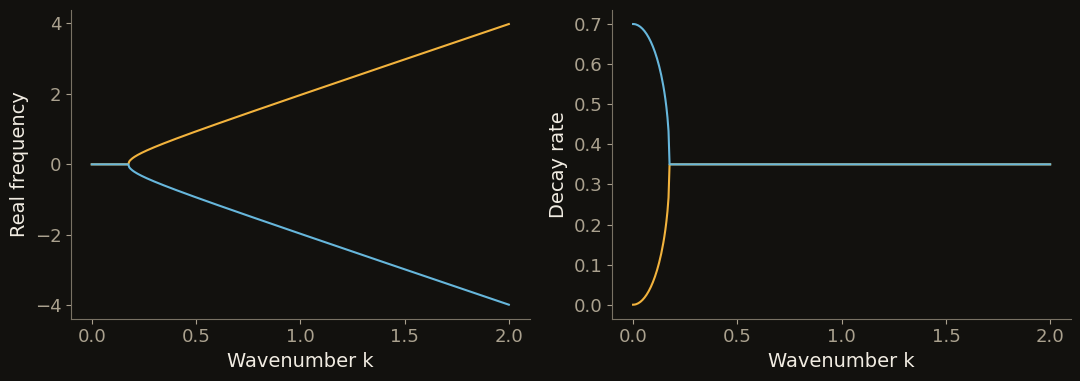

In [15]:
def wave_dispersion(k,speed=2.,damping=.7):
    root=np.sqrt((speed*np.asarray(k))**2-damping**2/4+0j)
    return -.5j*damping+root,-.5j*damping-root

k=np.linspace(0,2,401);plus,minus=wave_dispersion(k)
fig,ax=plt.subplots(1,2,figsize=(11,4))
for branch,color in [(plus,COLORS['amber']),(minus,COLORS['blue'])]:
    ax[0].plot(k,branch.real,color=color);ax[1].plot(k,-branch.imag,color=color)
ax[0].set(xlabel='Wavenumber k',ylabel='Real frequency');ax[1].set(xlabel='Wavenumber k',ylabel='Decay rate');plt.tight_layout();plt.show()
assert np.all(plus.imag<=1e-12) and np.all(minus.imag<=1e-12)


## Take Home Messages

- A few neighbors can coordinate a whole flock.
- Local alignment is faster than neighbor exchange.
- Persistent turning lets a turn travel as a wave.
- Weak damping lets the turn cross the flock without fading.

HTML slide 67.


## Fly counts reveal crowding

The measured count $N_b(t)$ gives a distribution $p_b(n)$ in each spatial bin. Compare that distribution with independent flies at the same mean, then fit a shared crowding cost and a location-dependent preference.

Méndez-Valderrama et al. (2018), [paper](https://doi.org/10.1038/s41467-018-05750-z), [data](https://osf.io/7ubz2/). The deposited rectangle variable includes `96flies` in its name, but observed frame totals are 56–66; the filename is not a population measurement.

HTML slides 68–70.

In [16]:
fly_dir=DATA/'flies/dfft-2018'
rect=loadmat(fly_dir/'figure-03-rectangle-high-occupancies.mat')['occ_rectangle_96flies'].astype(int)
c_low=loadmat(fly_dir/'figure-03-c-shape-low-occupancies.mat')['occ_C_2flies'].astype(int)
c_high=loadmat(fly_dir/'figure-03-c-shape-high-occupancies.mat')['occ_C_189flies'].astype(int)
square_low=loadmat(fly_dir/'figure-03-square-low-occupancies.mat')['occ_square_1fly'].astype(int)
square_high=loadmat(fly_dir/'figure-03-square-high-occupancies.mat')['occ_square_125flies'].astype(int)
areas=json.loads((fly_dir/'physical-bin-areas.json').read_text())['bin_area_cm2']
assert c_low.shape[1]==c_high.shape[1]==37
assert np.all(c_low.sum(axis=1)==2) and np.all(c_high.sum(axis=1)==189)
print({'rectangle_mean_observed_total':round(float(rect.sum(axis=1).mean()),2),'C_sparse_total':2,'C_crowded_total':189,'bin_areas_cm2':areas})

{'rectangle_mean_observed_total': 63.47, 'C_sparse_total': 2, 'C_crowded_total': 189, 'bin_areas_cm2': {'rectangle': 0.1493, 'square': 0.1389, 'stairs': 0.6065, 'c_shape': 0.3514}}


### Independent flies provide the fluctuation baseline

For independent flies, a small bin has approximately Poisson counts with mean $\bar n_b$:

$$p_b^{(0)}(n)=e^{-\bar n_b}\frac{\bar n_b^n}{n!},\qquad \operatorname{Var}(N_b)=\bar n_b.$$

Changing location preference changes the mean. At a fixed mean, the Poisson variance cannot change. The measured distribution is narrower, motivating an additional crowding cost.

For exactly fixed total population, the count is binomial: $N_b\sim\operatorname{Binomial}(N,q_b)$, where $q_b$ is a fly's probability of occupying bin $b$. Then $\operatorname{Var}(N_b)=Nq_b(1-q_b)$; small $q_b$ gives the Poisson approximation. The calculation uses an illustrative fixed population of 65.

HTML slides 71–72.


In [17]:
from scipy.stats import binom,poisson
N_reference=65
independent_n=np.arange(18)
q_reference=float(rect.mean(axis=0).max()/N_reference)
packet['independent_counts']={'N':N_reference,'q':q_reference,'n':independent_n,
 'binomial':binom.pmf(independent_n,N_reference,q_reference),'poisson':poisson.pmf(independent_n,N_reference*q_reference),
 'rectangle_variance':rect.var(axis=0,ddof=1)}

### A crowding cost penalizes high occupancy

We introduce a crowding cost $f_n$: a nonlinear penalty for having many flies in a bin. It is the total cost for $n$ flies. As an illustration, if each pair contributes $\epsilon$, there are $n(n-1)/2$ pairs, so $f_n=\epsilon n(n-1)/2$. Adding one fly increases the cost by $\epsilon n$. The fly experiment infers $f_n$ from counts; it does not assume this pairwise example.

HTML slide 73.


### Location preference and crowding determine the number distribution

$$p_b(n)=\frac{e^{-f_n-(V_b-\mu_{\rm occ})n}}{\mathcal Z_b\,n!}.$$

$V_b$ is an effective environmental potential: lower values make a location more favorable. It is dimensionless and inferred from occupancy, rather than a mechanical potential energy. $nV_b$ is the total location cost for $n$ flies. $f_n$ is the total crowding cost for $n$ flies, shared among all bins; it is not multiplied by $n$ again. $\mu_{\rm occ}$ is the same for all bins and sets the mean total, while $\mathcal Z_b$ normalizes each bin. Setting $f_n=0$ recovers a Poisson law. The single-bin model fixes the total on average.

HTML slides 74.

In [18]:
def count_probabilities(f,V,mu=0.):
    f=np.asarray(f,float);V=np.atleast_1d(V).astype(float);n=np.arange(len(f))
    log_weight=-f[None,:]-(V[:,None]-mu)*n-gammaln(n+1)
    return np.exp(log_weight-logsumexp(log_weight,axis=1,keepdims=True))

def count_mean(f,V,mu=0.):
    return count_probabilities(f,V,mu)@np.arange(len(f))

assert np.allclose(count_probabilities(np.zeros(50),[-1,0,1]).sum(axis=1),1)
assert np.allclose(count_mean(np.zeros(50),[-1,0,1]),np.exp(-np.array([-1,0,1])))

### Fit the crowding cost in the rectangle

All bins share $f_n$ and have separate $V_b$. Set $f_0=f_1=0$ to fix the constant and linear ambiguity. Fit the first 80% of observations, then compare held-out log probability with a Poisson baseline. The new-chamber crowded measurements are not used in this fit.

HTML slide 74.

{'held_out_gain_nats_per_bin_observation': 0.0565, 'training_occupancy_range': [0, 8]}


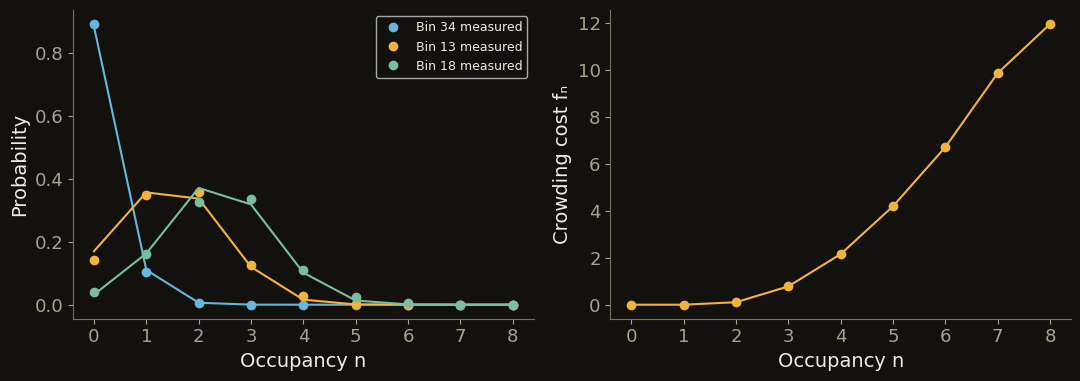

In [19]:
def fit_dfft(occupancies):
    a=np.asarray(occupancies,int);T,B=a.shape;nmax=int(a.max());n=np.arange(nmax+1)
    histogram=np.stack([np.bincount(a[:,b],minlength=nmax+1) for b in range(B)])
    mean=a.mean(axis=0)
    def objective(parameters):
        f=np.r_[0.,0.,parameters[:nmax-1]];V=parameters[nmax-1:]
        logw=-f[None,:]-V[:,None]*n-gammaln(n+1)
        logz=logsumexp(logw,axis=1)
        p=np.exp(logw-logz[:,None])
        loss=(T*logz.sum()+(histogram*(f[None,:]+V[:,None]*n+gammaln(n+1))).sum())/(T*B)
        grad_f=(histogram.sum(axis=0)-T*p.sum(axis=0))[2:]/(T*B)
        grad_v=(T*mean-T*(p@n))/(T*B)
        return loss,np.r_[grad_f,grad_v]
    initial=np.r_[np.zeros(nmax-1),-np.log(np.maximum(mean,1e-8))]
    opt=minimize(objective,initial,jac=True,method='L-BFGS-B',options={'maxiter':2500,'gtol':1e-9,'ftol':1e-12})
    if not opt.success: raise RuntimeError(opt.message)
    return np.r_[0.,0.,opt.x[:nmax-1]],opt.x[nmax-1:],float(opt.fun)

split=int(.8*len(rect))
f_rect,V_rect,train_nll=fit_dfft(rect[:split])
prob_rect=count_probabilities(f_rect,V_rect)
observed_prob=np.stack([np.bincount(rect[:,b],minlength=len(f_rect))/len(rect) for b in range(rect.shape[1])])
held=rect[split:]
# The baseline uses the full Poisson law; DFFT uses its declared measured count support.
lam=rect[:split].mean(axis=0)
poisson_log=held*np.log(lam)-lam-gammaln(held+1)
dfft_log=np.log(np.maximum(prob_rect[np.arange(held.shape[1])[None,:],held],1e-300))
ll_gain=float(np.mean(dfft_log-poisson_log))
assert np.isfinite(ll_gain)
print({'held_out_gain_nats_per_bin_observation':round(ll_gain,4),'training_occupancy_range':[0,len(f_rect)-1]})
fig,ax=plt.subplots(1,2,figsize=(11,4))
chosen=np.argsort(rect.mean(axis=0))[[10,25,40]]
n=np.arange(len(f_rect))
for b,c in zip(chosen,[COLORS['blue'],COLORS['amber'],COLORS['green']]):
    ax[0].plot(n,observed_prob[b],'o',color=c,label=f'Bin {b+1} measured')
    ax[0].plot(n,prob_rect[b],color=c)
ax[0].set(xlabel='Occupancy n',ylabel='Probability',xticks=n);ax[0].legend(fontsize=9)
ax[1].plot(n,f_rect,'o-',color=COLORS['amber']);ax[1].set(xlabel='Occupancy n',ylabel='Crowding cost fₙ',xticks=n)
plt.tight_layout();plt.show()

### The fitted crowding cost is the same across the temperature gradient

$$-\ln[n!p_b(n)]=f_n+(V_b-\mu_{\rm occ})n+\ln\mathcal Z_b.$$

Bins at different positions have different location preferences, but their inferred crowding costs agree approximately. The slide marks the three locations on the chamber and compares their crowding costs directly. The transformation below is retained here to show the extraction.

The rectangle fit absorbs $\mu_{\rm occ}$ into the location costs. Colored curves show the transformed measured distributions. Subtracting each bin's fitted line leaves an estimate of the shared crowding cost $f_n$; the white curve is the shared fit. Empty histogram values are omitted from the logarithmic display.

HTML slides 75.

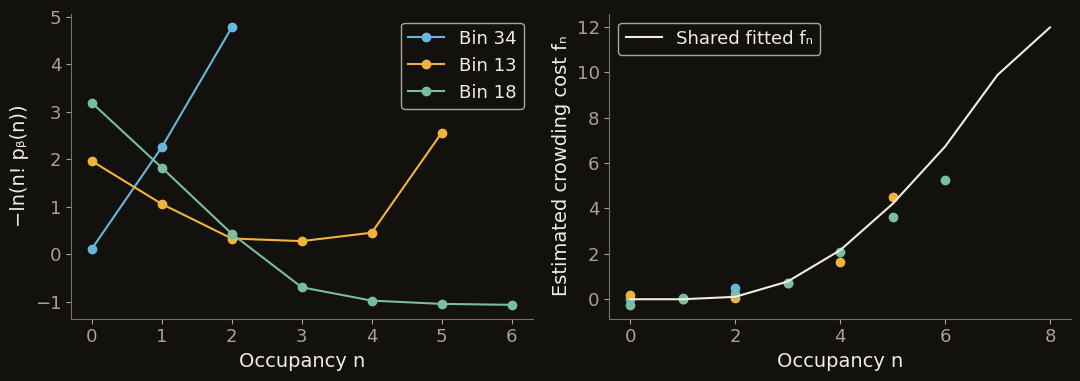

In [20]:
logz=logsumexp(-f_rect[None,:]-V_rect[:,None]*n-gammaln(n+1),axis=1)
pseudo=-np.log(np.where(observed_prob>0,observed_prob,np.nan))-gammaln(n+1)
collapsed=pseudo-V_rect[:,None]*n-logz[:,None]
fig,ax=plt.subplots(1,2,figsize=(11,4))
for b,c in zip(chosen,[COLORS['blue'],COLORS['amber'],COLORS['green']]):
    ax[0].plot(n,pseudo[b],'o-',color=c,label=f'Bin {b+1}')
    ax[1].plot(n,collapsed[b],'o',color=c)
ax[1].plot(n,f_rect,color=COLORS['ink'],label='Shared fitted fₙ')
ax[0].set(xlabel='Occupancy n',ylabel='−ln(n! pᵦ(n))');ax[1].set(xlabel='Occupancy n',ylabel='Estimated crowding cost fₙ');ax[0].legend();ax[1].legend();plt.tight_layout();plt.show()

### Transfer the measured crowding cost to a new chamber

The crowded rectangle supplies $f_n$. Two flies supply the preference in the C-shaped chamber; its 189-fly distribution is reserved for the prediction test.

Transfer at equal physical density, using $f_n\simeq A f_{\rm loc}(n/A)$:

$$a=\frac{A_{\rm new}}{A_{\rm old}},\qquad f_{\rm new}(n)=a f_{\rm old}(n/a).$$

The bin areas are 0.1493 cm² (rectangle) and 0.3514 cm² (C-shaped). Keep interpolation within the supported density range, infer the new location costs from sparse occupancy, and choose one multiplier so the predicted total is 189.

HTML slides 76–77.

{'C_chamber_naive_RMSE_flies_per_bin': 3.657, 'C_chamber_DFFT_RMSE': 1.2, 'mu': 5.495}


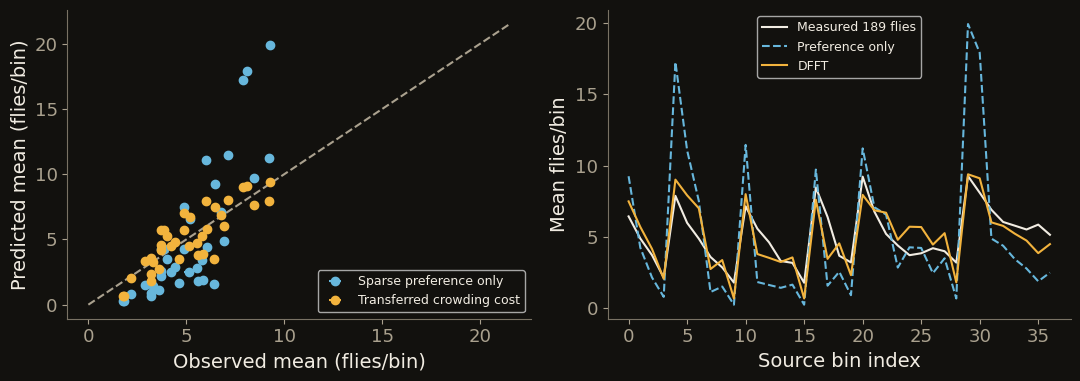

In [21]:
def rescale_cost(f,area_old,area_new):
    ratio=area_new/area_old
    n_new=np.arange(int(np.floor((len(f)-1)*ratio))+1)
    values=CubicSpline(np.arange(len(f))*ratio,np.asarray(f)*ratio)(n_new)
    # The spline arguments already include both area rescalings; remove its linear gauge.
    return values-values[0]-n_new*(values[1]-values[0])

def infer_preference_from_mean(f,means):
    return np.array([brentq(lambda V:count_mean(f,[V])[0]-m,-60,60) for m in means])

def predict_total(f,V,total):
    mu=brentq(lambda value:count_mean(f,V,value).sum()-total,-60,60)
    return count_mean(f,V,mu),float(mu)

f_c=rescale_cost(f_rect,areas['rectangle'],areas['c_shape'])
V_c=infer_preference_from_mean(f_c,c_low.mean(axis=0))
pred_c,mu_c=predict_total(f_c,V_c,189)
naive_c=189*c_low.mean(axis=0)/c_low.sum(axis=1).mean()
obs_c=c_high.mean(axis=0)
blocks=np.array_split(c_high,8)
sem_c=np.std([b.mean(axis=0) for b in blocks],axis=0,ddof=1)/np.sqrt(8)
rmse_naive=float(np.sqrt(np.mean((naive_c-obs_c)**2)))
rmse_dfft=float(np.sqrt(np.mean((pred_c-obs_c)**2)))
assert np.isclose(pred_c.sum(),189)
print({'C_chamber_naive_RMSE_flies_per_bin':round(rmse_naive,3),'C_chamber_DFFT_RMSE':round(rmse_dfft,3),'mu':round(mu_c,3)})
fig,ax=plt.subplots(1,2,figsize=(11,4))
maxn=max(obs_c.max(),naive_c.max())*1.08
ax[0].errorbar(obs_c,naive_c,xerr=sem_c,fmt='o',color=COLORS['blue'],label='Sparse preference only')
ax[0].errorbar(obs_c,pred_c,xerr=sem_c,fmt='o',color=COLORS['amber'],label='Transferred crowding cost')
ax[0].plot([0,maxn],[0,maxn],ls='--',color=COLORS['muted']);ax[0].set(xlabel='Observed mean (flies/bin)',ylabel='Predicted mean (flies/bin)');ax[0].legend(fontsize=9)
ax[1].plot(obs_c,color=COLORS['ink'],label='Measured 189 flies');ax[1].plot(naive_c,color=COLORS['blue'],ls='--',label='Preference only');ax[1].plot(pred_c,color=COLORS['amber'],label='DFFT');ax[1].set(xlabel='Source bin index',ylabel='Mean flies/bin');ax[1].legend(fontsize=9);plt.tight_layout();plt.show()

### Test the same procedure in a square chamber

One fly supplies the sparse preference; the crowded recording contains about 125 flies in 49 bins. The prediction uses nominal total 125, the new sparse preference, and the same rectangle-derived crowding cost after area conversion.

HTML slides 78.

Square mean-density comparison: {'rmse_naive': 1.979, 'rmse_dfft': 0.775, 'mean_detected_total': 124.019}


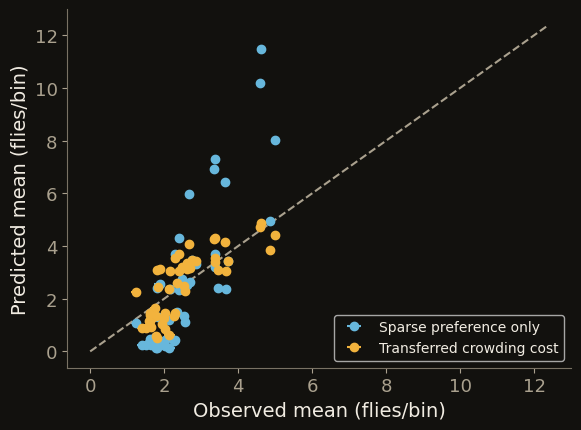

In [22]:
f_square=rescale_cost(f_rect,areas['rectangle'],areas['square'])
V_square=infer_preference_from_mean(f_square,square_low.mean(axis=0))
pred_square,mu_square=predict_total(f_square,V_square,125)
naive_square=125*square_low.mean(axis=0)
obs_square=square_high.mean(axis=0)
square_sem=np.std([b.mean(axis=0) for b in np.array_split(square_high,8)],axis=0,ddof=1)/np.sqrt(8)
square_result={'f':f_square,'V':V_square,'mu':mu_square,'predicted':pred_square,'naive':naive_square,
 'observed':obs_square,'sem':square_sem,'sparse_mean':square_low.mean(axis=0),'nominal_total':125,
 'mean_detected_total':float(square_high.sum(axis=1).mean()),
 'rmse_naive':float(np.sqrt(np.mean((naive_square-obs_square)**2))),
 'rmse_dfft':float(np.sqrt(np.mean((pred_square-obs_square)**2)))}
assert np.isclose(pred_square.sum(),125)
print('Square mean-density comparison:', {k:round(square_result[k],3) for k in ['rmse_naive','rmse_dfft','mean_detected_total']})
fig,ax=plt.subplots(figsize=(6,4.5))
ax.errorbar(obs_square,naive_square,xerr=square_sem,fmt='o',color=COLORS['blue'],label='Sparse preference only')
ax.errorbar(obs_square,pred_square,xerr=square_sem,fmt='o',color=COLORS['amber'],label='Transferred crowding cost')
limit=max(naive_square.max(),obs_square.max())*1.08
ax.plot([0,limit],[0,limit],'--',color=COLORS['muted']);ax.set(xlabel='Observed mean (flies/bin)',ylabel='Predicted mean (flies/bin)');ax.legend(fontsize=10);plt.tight_layout();plt.show()

### Compare predictions with the crowded measurements

Show preference-only prediction, prediction with crowding, and measurement on a common scale. The scatter plots compare predicted and observed means; the diagonal denotes exact agreement. Horizontal intervals are SEMs across eight contiguous observation blocks. The exported mean-density RMSEs are 3.66 versus 1.20 flies/bin in the C-shaped chamber and 1.98 versus 0.78 in the square. The replay uses source observation number.
HTML slides 77–78.


In [23]:
from scipy.ndimage import zoom

def small_bin_map(path,variable,max_side=150):
    a=loadmat(path)[variable]
    step=max(1,int(np.ceil(max(a.shape)/max_side)))
    return a[::step,::step].astype(int)

packet['flies']={'f':f_rect,'V_rectangle':V_rect,'observed_probability':observed_prob,'probability':prob_rect,
                 'pseudo':pseudo,'collapsed':collapsed,'chosen_bins':chosen,'rectangle_means':rect.mean(axis=0),
                 'rectangle_counts':rect[::25], 'rectangle_mask':small_bin_map(fly_dir/'figure-03-rectangle-bins.mat','bins_f'),
                 'c_mask':small_bin_map(fly_dir/'figure-03-c-shape-bins.mat','bins'),
                 'c_sparse_mean':c_low.mean(axis=0),'c_observed':obs_c,'c_naive':naive_c,'c_predicted':pred_c,'c_sem':sem_c,
                 'c_f':f_c,'c_V':V_c,'c_mu':mu_c,'areas_cm2':areas,'held_out_gain':ll_gain,
                 'rmse_naive':rmse_naive,'rmse_dfft':rmse_dfft,'count_support':[0,len(f_rect)-1]}
square_result['mask']=small_bin_map(fly_dir/'figure-03-square-bins.mat','bins')
packet['flies']['square']=square_result

### From bin counts to a continuous density

The new-chamber test predicted where a whole population accumulates from crowding and habitat preference. We can express the same ingredients as a theory of continuous density.

For a stationary profile, divide the mean count by bin area: $\rho(\mathbf x_b)\simeq\langle N_b\rangle/A_b$. Average over individual fluctuations but retain variation across the chamber. Number conservation becomes $\int\rho\,d^2x=N$.

The discrete ingredients carry over: $f_n\simeq A_b f_{\rm loc}(n/A_b)$ and $nV_b\simeq A_b\rho V_{\rm env}$. A sum of bin costs becomes an integral of cost per area:

$$\mathcal H_{\rm DFFT}[\rho]=\int[f_{\rm loc}(\rho)+V_{\rm env}(\mathbf x)\rho]d^2x.$$

The following helper evaluates the full density functional: ideal counting entropy, crowding, and environment. It uses the continuous limit $\rho\ln\rho\to0$ at zero density. The local approximation assumes the crowding cost depends on the density at that location. The measured low-occupancy fly prediction above retains the discrete count distributions.

HTML slides 79–80.


In [24]:
def density_functional(rho,V,area=1.,crowding=1.,rho_ref=1.):
    """Full local density cost, including ideal counting entropy."""
    rho=np.asarray(rho,float);V=np.asarray(V,float)
    if np.any(rho<0) or rho_ref<=0:
        raise ValueError('Density must be nonnegative and reference density positive')
    positive=rho>0
    entropy=float(area*np.sum(rho[positive]*(np.log(rho[positive]/rho_ref)-1)))
    environment=float(area*np.dot(V,rho))
    interaction=float(.5*area*crowding*np.dot(rho,rho))
    return dict(entropy=entropy,environment=environment,interaction=interaction,
                total=entropy+environment+interaction)

# The zero-density limit is finite; the derivative recovers the chemical potential.
assert density_functional([0.],[0.])['total']==0.
rho_test=np.array([.4,1.2,3.]);V_test=np.array([0.,.5,1.]);area_test=.7;g_test=.3
for i in range(len(rho_test)):
    step=np.zeros_like(rho_test);step[i]=1e-6
    derivative=(density_functional(rho_test+step,V_test,area_test,g_test)['total']-
                density_functional(rho_test-step,V_test,area_test,g_test)['total'])/(2e-6*area_test)
    assert np.isclose(derivative,np.log(rho_test[i])+g_test*rho_test[i]+V_test[i],atol=1e-8)

profile_x=np.linspace(0,1,48)
profile_V=3*profile_x
profile_flat=np.full(48,2.)
profile_biased=np.exp(-profile_V);profile_biased*=96/profile_biased.sum()
assert np.isclose(profile_flat.sum(),profile_biased.sum())
packet['functional']={'x':profile_x,'V':profile_V,'flat':profile_flat,'biased':profile_biased}

### Density Functional Theory predicts a density profile

Density Functional Theory (DFT) assigns a cost to an entire density profile and minimizes it at fixed population. A functional takes a function, here $\rho(\mathbf x)$, as input and returns one number.

$$\mathcal G_{\rm occ}[\rho]=\int\left[\rho\left(\ln\frac{\rho}{\rho_{\rm ref}}-1\right)+f_{\rm loc}(\rho)+V_{\rm env}\rho\right]d^2x.$$

The first term is the standard ideal-particle entropy contribution: spreading particles among locations permits more arrangements. The remaining terms are the same crowding and environmental contributions as in the bin model. Costs are dimensionless; $\rho_{\rm ref}$ is a fixed reference density.

Enforce the fixed population using a Lagrange multiplier:

$$\mathcal G_{\rm occ}[\rho]-\mu_{\rm occ}\left(\int\rho\,d^2x-N\right).$$

Here $\mu_{\rm occ}$ is the **effective chemical potential**, the continuum counterpart of the multiplier in the bin probabilities. It is a dimensionless statistical cost per added animal, rather than a measured mechanical energy. Moving a small amount of population from B to A lowers the cost if adding particles costs less at A. At a minimum the marginal cost must therefore be equal everywhere. Differentiating the three local terms gives

$$\frac{\delta\mathcal G_{\rm occ}}{\delta\rho}=\ln\frac{\rho}{\rho_{\rm ref}}+f'_{\rm loc}(\rho)+V_{\rm env}=\mu_{\rm occ}.$$

The same $\mu_{\rm occ}$ applies at every position, chosen so $\int\rho\,d^2x=N$. Without crowding, $\rho\propto e^{-V_{\rm env}}$. For the illustrative choice $f_{\rm loc}=g\rho^2/2$, the crowding contribution to the marginal cost is $g\rho$. Increasing positive $g$ spreads the density out. Changing the environment or crowding predicts a new profile without simulating individual trajectories.

The example uses a linear location cost $V_{\rm env}(x)=s x$, where $s$ is the slope controlled by the HTML slider. The calculation below uses dimensionless density in equal-area cells and fixes total population. It illustrates the smooth-density approximation, rather than refitting the fly data. The earlier experimental prediction sums discrete count probabilities.

HTML slides 80–82.


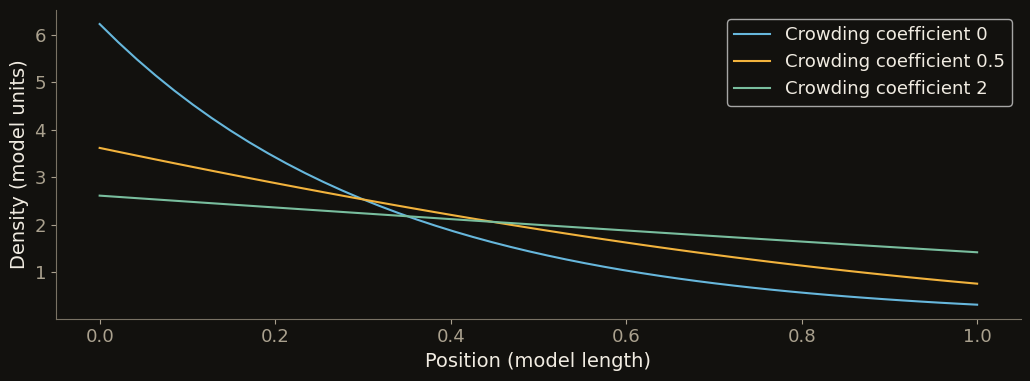

In [25]:
def density_profile(potential,total=96.,crowding=.5):
    potential=np.asarray(potential,float)
    def at_mu(mu):
        target=mu-potential
        log_rho=np.minimum(target, np.log(np.maximum(np.abs(target)+1,1)/max(crowding,1e-12))) if crowding>0 else target.copy()
        for _ in range(60):
            rho=np.exp(log_rho)
            log_rho-=(log_rho+crowding*rho-target)/(1+crowding*rho)
        return np.exp(log_rho)
    mu=brentq(lambda value:at_mu(value).sum()-total,-30,50)
    return at_mu(mu),mu

profile_coordinate=np.linspace(0,1,48);potential=3*profile_coordinate
fig,ax=plt.subplots()
for g,color in [(0.,COLORS['blue']),(.5,COLORS['amber']),(2.,COLORS['green'])]:
    density,mu=density_profile(potential,crowding=g)
    assert np.isclose(density.sum(),96.)
    assert np.allclose(np.log(density)+g*density+potential,mu,atol=1e-10)
    ax.plot(profile_coordinate,density,color=color,label=f'Crowding coefficient {g:g}')
ax.set(xlabel='Position (model length)',ylabel='Density (model units)');ax.legend();plt.tight_layout();plt.show()


## DFT describes electrons, liquids, and animal crowds

Electronic DFT uses electron density to calculate ground-state energies and bonding in molecules and solids. Classical DFT uses particle density to predict fluid interfaces and packing near walls. The fly model uses animal density to predict accumulation from habitat preference and crowding. The functionals contain different physics: energy for electronic ground states, free energy for thermal fluids, and inferred dimensionless statistical costs for this animal model.

References: [Kohn, Nobel lecture](https://www.nobelprize.org/uploads/2018/06/kohn-lecture.pdf); [Ebner, Saam & Stroud, Physical Review A 14, 2264–2273 (1976)](https://doi.org/10.1103/PhysRevA.14.2264).

HTML slide 83.


## Take Home Messages

- Count fluctuations reveal the effects of crowding.
- Separating crowding from habitat preference lets us predict density in a new environment.
- Density Functional Theory predicts the density profile without tracking individual animals.

HTML slide 84.


## Take Home Messages

- **Fish.** Local responses produce schools and mills, group decisions, and collective sensing.
- **Locusts.** Contact helps initiate walking; vision guides direction.
- **Birds.** Persistent turning and weak damping carry a local turn across the flock.
- **Flies.** Separating habitat preference from crowding lets us predict density in a new environment.

HTML slide 85.


## Numerical checks and browser export

Compare deterministic calculations in Python and JavaScript, then export the prepared data used by the HTML lecture.

In [26]:
fixtures={
 'body':{'displacement':np.array([[3.,4.],[-2.,1.]]),'velocity':np.array([[0.,2.],[3.,4.]])},
 'count':{'f':np.array([0.,0.,.2,.7,1.6,3.]),'V':np.array([-1.,0.,1.]),'mu':.3},
 'wave':{'angle':np.array([0.,.2,.4,.1,-.1]),'rate':np.array([.1,0.,-.1,0.,.05]),'dt':.004,'dx':.125},
 'rule':{'x':40.,'y':25.,'delta':.4,'alignment':1.2,'attraction':.8,'repulsion':1.5},
}
fixtures['body']['expected']=body_coordinates(fixtures['body']['displacement'],fixtures['body']['velocity'])
fixtures['count']['expected']=count_probabilities(fixtures['count']['f'],fixtures['count']['V'],fixtures['count']['mu'])
for model in ['wave','diffusion']:
    fixtures['wave'][model]=propagation_step(fixtures['wave']['angle'],fixtures['wave']['rate'],.004,.125,model=model)
fixtures['rule']['expected']=interaction_rule(**{k:fixtures['rule'][k] for k in ['x','y','delta','alignment','attraction','repulsion']})
fixtures['pair']={'position':np.array([[55.,2.],[0.,0.]]),'heading':np.array([.2,0.]),'speed':np.array([50.,48.]),'time':1.,'dt':.01}
for mode in ['alignment','position']:
    fixtures['pair'][mode+'_expected']=pair_model_step(fixtures['pair']['position'],fixtures['pair']['heading'],fixtures['pair']['speed'],1.,.01,mode)
fixtures['functional']={'rho':np.array([1.,2.,3.]),'V':np.array([0.,1.,2.]),'area':.5,'crowding':.3}
fixtures['functional']['expected']=density_functional(**fixtures['functional'])
fixtures['extended']={
 'triplet':triplet_prediction(pair_example),
 'informed':informed_heading_step(heading_start,.2,1.3,.8,.03),
 'sensing':sensing_step(np.array([-20.,4.,.3]),3.,.02,12.,4.),
 'kernel':ring_kernel(24,1.2,.7),
 'profile':density_profile(np.linspace(0,3,48),96.,.5),
 'dispersion':[[v.real.tolist(),v.imag.tolist()] for v in wave_dispersion(np.array([0.,.1,.5,1.]),2.,.7)]
}
packet['validation']=fixtures

def json_ready(value):
    if isinstance(value,np.ndarray):return json_ready(value.tolist())
    if isinstance(value,(np.floating,float)):return round(float(value),6) if np.isfinite(value) else None
    if isinstance(value,np.integer):return int(value)
    if isinstance(value,dict):return {str(k):json_ready(v) for k,v in value.items()}
    if isinstance(value,(tuple,list)):return [json_ready(v) for v in value]
    return value

# Fixtures retain full precision; scientific display/replay payloads use six decimal places.
fixture_path=OUT/'lecture-15-validation.json'
def precise(value):
    if isinstance(value,np.ndarray):return value.tolist()
    if isinstance(value,(np.integer,np.floating)):return value.item()
    if isinstance(value,dict):return {k:precise(v) for k,v in value.items()}
    if isinstance(value,(tuple,list)):return [precise(v) for v in value]
    return value
fixture_path.write_text(json.dumps(precise(fixtures),indent=2,allow_nan=False)+'\n')
packet['summary']={'fish_encounters':len(enc),'dfft_heldout_gain':ll_gain,
                   'c_rmse_naive':rmse_naive,'c_rmse_dfft':rmse_dfft,'square_rmse_naive':square_result['rmse_naive'],'square_rmse_dfft':square_result['rmse_dfft']}
output=OUT/'lecture-15-browser-data.js'
output.write_text('/* Generated by the executed Lecture 15 Python companion. */\nwindow.LECTURE15_DATA='+json.dumps(json_ready(packet),separators=(',',':'),allow_nan=False)+';\n')
print(f'Browser dataset written ({output.stat().st_size/1e6:.2f} MB).')
print('Normalization, observed totals, normal-acceleration orthogonality and deterministic fixtures checked.')
# Reproducible provenance for the browser payload; code-cell hash excludes saved outputs.
import hashlib
import importlib.metadata
import nbformat
companion=ROOT/'lectures/lecture-15-animal-interaction-rules.ipynb'
source_nb=nbformat.read(companion,4)
code_sources='\n\n'.join(c.source for c in source_nb.cells if c.cell_type=='code')
inputs=[DATA/'flocking/fish-pairs-2021.npz',fly_dir/'physical-bin-areas.json']
inputs+=sorted(fly_dir.glob('*.mat'))
manifest={'companion':str(companion.relative_to(ROOT)),'code_cells_sha256':hashlib.sha256(code_sources.encode()).hexdigest(),
 'inputs':[{ 'path':str(p.relative_to(ROOT)), 'bytes':p.stat().st_size,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for p in inputs],
 'browser_payload':{'path':str(output.relative_to(ROOT)),'bytes':output.stat().st_size,'sha256':hashlib.sha256(output.read_bytes()).hexdigest(),'precision_decimal_places':6},
 'versions':{name:importlib.metadata.version(name) for name in ['numpy','scipy','pandas','matplotlib','nbformat']},
 'summary':json_ready(packet['summary']),
 'interpretation':{'fish':'Conditional turning and speed responses from 40 pair trials; identities are local to each trial.',
 'fly_transfer':'Shared nonparametric cost from rectangle first 80%; C-sparse bin means determine V; physical area rescaling follows author script; C-crowded data only evaluate prediction.',
 'fly_uncertainty':'SEM of eight contiguous observation blocks; no claim of biological replication or independent time samples.',
 'movie':'Golden-shiner experimental footage has no verified matching trajectory file; quantitative fish responses use the separate pair dataset.',
 'local_alignment':'Mora published starling results motivate deterministic local-mode illustrations; no new Mora parameter fit is claimed.'}}
(OUT/'lecture-15-data-manifest.json').write_text(json.dumps(manifest,indent=2,allow_nan=False)+'\n')
print('Input hashes, code-source hash, package versions and processing manifest recorded.')

Browser dataset written (0.89 MB).
Normalization, observed totals, normal-acceleration orthogonality and deterministic fixtures checked.


Input hashes, code-source hash, package versions and processing manifest recorded.
